In [23]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

##### Data preparation

In [2]:
# Check the data
df = pd.read_csv("data/water_potability.csv")

# Change column_names to lower
df.columns = df.columns.str.lower()

df.head()

,ph,hardness,solids,chloramines,sulfate,conductivity,organic_carbon,trihalomethanes,turbidity,potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [3]:
# Check the total of missing values
missing_perc = round(df.isnull().mean() * 100, 2)
missing_perc

ph                 14.99
hardness            0.00
solids              0.00
chloramines         0.00
sulfate            23.84
conductivity        0.00
organic_carbon      0.00
trihalomethanes     4.95
turbidity           0.00
potability          0.00
dtype: float64

In [4]:
df.info() # Get the information per column
df.duplicated().sum() # Check if there are any duplicates

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   hardness         3276 non-null   float64
 2   solids           3276 non-null   float64
 3   chloramines      3276 non-null   float64
 4   sulfate          2495 non-null   float64
 5   conductivity     3276 non-null   float64
 6   organic_carbon   3276 non-null   float64
 7   trihalomethanes  3114 non-null   float64
 8   turbidity        3276 non-null   float64
 9   potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


np.int64(0)

In [5]:
# Check target column
df["potability"].unique()

array([0, 1])

**Data preparation conclusions**

The dataset has no duplicate rows and contains only numeric columns. Three columns have missing values: `ph` (15%), `sulfate` (24%) and `trihalomethanes` (5%). These are not imputed yet: imputation is done after the train/validation/test split, using the median of the training set only, to avoid data leakage. The target column `potability` only contains 0 and 1, as expected.

##### Split the data

In [6]:
# Split the data where we use stratify on potability so each set keeps the same class ratio of 61 and 39%
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df["potability"])
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1, stratify=df_full_train["potability"]
)

# Reset the index so each set starts at 0 
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [7]:
# Get the target-values
y_train = df_train.potability.values
y_val = df_val.potability.values
y_test = df_test.potability.values

del df_train['potability']
del df_val['potability']
del df_test['potability']

##### EDA

In [10]:
# Get some statistics
df_full_train.describe()

,ph,hardness,solids,chloramines,sulfate,conductivity,organic_carbon,trihalomethanes,turbidity,potability
count,2232.000000,2620.000000,2620.000000,2620.000000,1979.000000,2620.000000,2620.000000,2483.000000,2620.000000,2620.000000
mean,7.091592,196.591996,21987.430308,7.128758,333.418344,425.165369,14.270879,66.163544,3.976569,0.390076
std,1.596927,32.958427,8812.543530,1.573704,41.410457,80.674219,3.313843,16.280517,0.777095,0.487860
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.104627,177.174300,15523.393253,6.128831,307.648006,365.051472,12.033868,55.623130,3.439608,0.000000
50%,7.042230,197.624538,20982.439792,7.144281,332.349949,420.884959,14.189459,66.270477,3.965167,0.000000
75%,8.066329,216.675562,27310.587732,8.109320,359.683593,481.309989,16.517104,77.349886,4.510583,1.000000
max,13.541240,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [11]:
# Check the class distribution of the target (as fractions)
class_dist = df_full_train["potability"].value_counts(normalize=True)
class_dist

potability
0    0.609924
1    0.390076
Name: proportion, dtype: float64

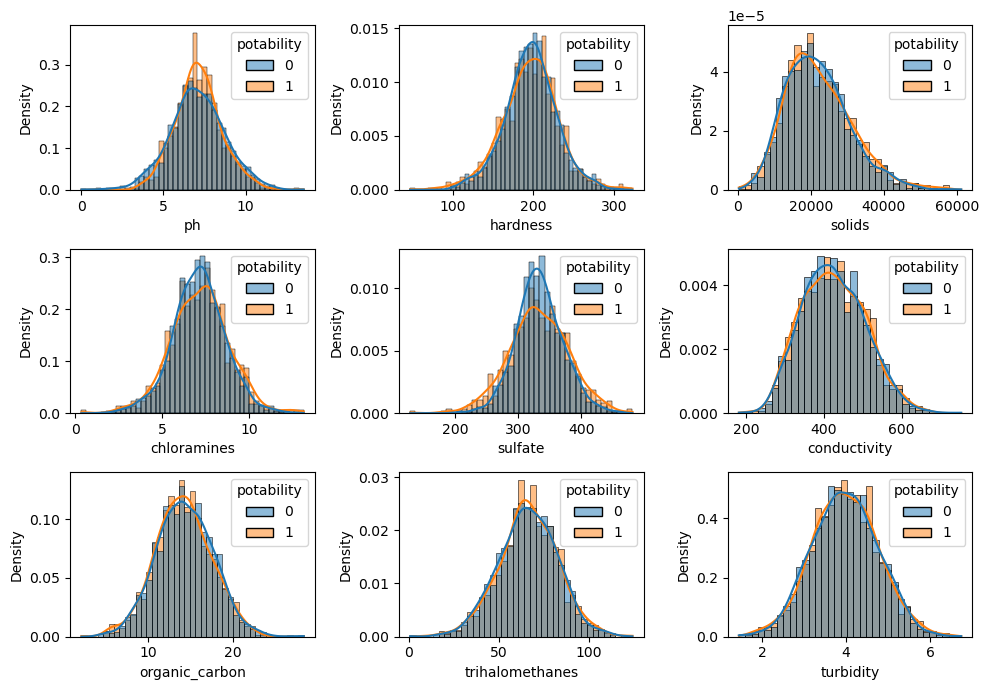

In [18]:
# Plot the distribution of every feature, split by the target
features = df_full_train.columns.drop("potability")

# Create a 3 x 3 grid of plots
fig, axes = plt.subplots(3, 3, figsize=(10, 7))

# Pair each feature with its own subplot
for col, ax in zip(features, axes.flat):
    # Density per class, so the larger class doesn't dominate
    sns.histplot(data=df_full_train, x=col, hue="potability", kde=True,
                 stat="density", common_norm=False, ax=ax)

# Prevent overlapping titles and show the plots
plt.tight_layout()
plt.show()

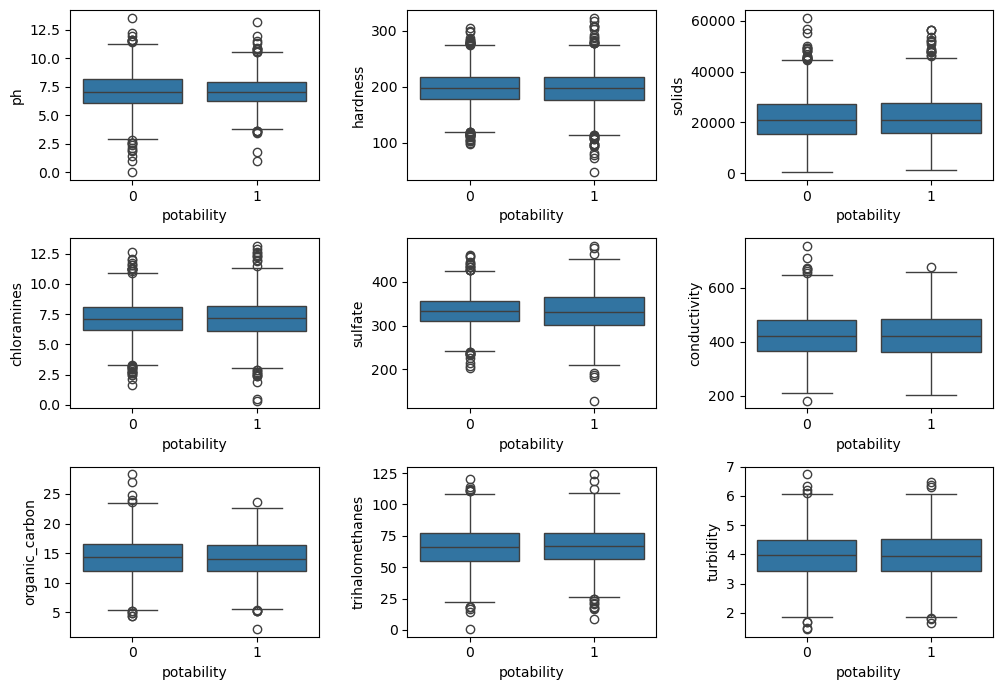

In [19]:
# Check the outliers with boxplots
fig, axes = plt.subplots(3, 3, figsize=(10, 7))

for col, ax in zip(features, axes.flat):
    sns.boxplot(data=df_full_train, x="potability", y=col, ax=ax)

plt.tight_layout()
plt.show()

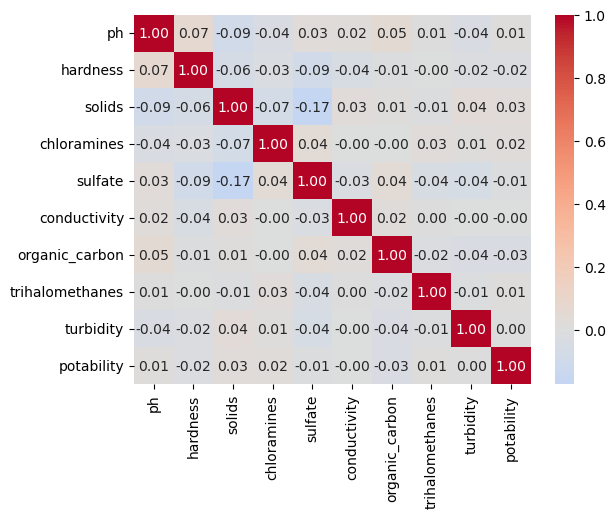

In [21]:
# Check the correlations with a heatmap
sns.heatmap(df_full_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

In [22]:
# Check if missing values are related to the target
for col in ["ph", "sulfate", "trihalomethanes"]:
    rate = df_full_train.groupby(df_full_train[col].isnull())["potability"].mean()
    print(f"{col}: present={rate[False]:.3f}, missing={rate[True]:.3f}")

ph: present=0.393, missing=0.374
sulfate: present=0.395, missing=0.374
trihalomethanes: present=0.393, missing=0.336


In [24]:
# Compute the ROC AUC of each feature on its own
for col in features:
    mask = df_full_train[col].notnull()
    auc = roc_auc_score(df_full_train.loc[mask, "potability"], df_full_train.loc[mask, col])
    print(f"{col}: {max(auc, 1 - auc):.3f}")

ph: 0.506
hardness: 0.507
solids: 0.512
chloramines: 0.512
sulfate: 0.504
conductivity: 0.500
organic_carbon: 0.518
trihalomethanes: 0.508
turbidity: 0.502


In [25]:
# Check if distance from neutral pH (7) is more predictive than pH itself
mask = df_full_train["ph"].notnull()
ph_dist = abs(df_full_train.loc[mask, "ph"] - 7)

auc = roc_auc_score(df_full_train.loc[mask, "potability"], ph_dist)
print(f"abs(ph - 7): {max(auc, 1 - auc):.3f}")

abs(ph - 7): 0.563


In [26]:
# Add distance from neutral pH as an extra feature (potable water is closer to pH 7)
def add_features(df):
    df = df.copy()
    df["ph_dist"] = abs(df["ph"] - 7)
    return df

df_full_train = add_features(df_full_train)
df_train = add_features(df_train)
df_val = add_features(df_val)
df_test = add_features(df_test)

**EDA conclusions**

The target is moderately imbalanced (61/39), so ROC AUC is used as the main metric. The features are roughly normally distributed, the missing values appear random and the outliers look plausible, so median imputation will be used and the outliers are kept. No single feature is predictive on its own: correlations with the target are close to 0 and the single-feature ROC AUC is 0.50–0.52. The histograms did show that potable water has a narrower pH range around 7, and the distance from neutral pH (`abs(ph - 7)`) reaches a ROC AUC of 0.563, so this feature is added. Because the relations are non-linear, tree-based models are expected to perform best.